## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Giới thiệu bài toán và dữ liệu

#### 1.1. Bài toán

- **Bối cảnh:** dữ liệu ghi lại các cuộc gọi marketing trực tiếp của một ngân hàng nhằm mời khách hàng gửi tiền kỳ hạn.
- **Mục tiêu:** dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không, giúp ngân hàng ưu tiên liên hệ nhóm khách tiềm năng và giảm chi phí cuộc gọi.
- **Input:** thông tin khách hàng và chiến dịch marketing (tuổi, nghề nghiệp, lịch sử liên hệ, chỉ số kinh tế vĩ mô...).
- **Output:** `yes` (đăng ký) hoặc `no` (không đăng ký).
- **Loại bài toán:** học có giám sát, phân loại nhị phân (Classification).

#### 1.2. Dữ liệu

Nguồn: UCI Bank Marketing, tệp `bank-additional-full.csv`, gồm 41.188 mẫu và 21 cột (20 thuộc tính và biến mục tiêu `y`).

| Nhóm thuộc tính | Các cột |
|---|---|
| Thông tin khách hàng | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` |
| Thông tin lần liên hệ hiện tại | `contact`, `month`, `day_of_week`, `duration` |
| Lịch sử chiến dịch | `campaign`, `pdays`, `previous`, `poutcome` |
| Chỉ số kinh tế vĩ mô | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |
| Biến mục tiêu | `y` |

Cột `duration` (thời lượng cuộc gọi) chỉ biết sau khi cuộc gọi kết thúc nên sẽ được loại bỏ ở mục 3 để tránh rò rỉ thông tin.

#### 1.3. Đọc dữ liệu

In [1]:
import pandas as pd

df = pd.read_csv("data/bank-additional-full.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 2. Khám phá dữ liệu (EDA)

#### 2.1. Tổng quan dữ liệu

Kiểm tra kích thước, kiểu dữ liệu và giá trị thiếu. Các cột đều có đủ 41.188 giá trị (không có ô trống), tuy nhiên một số cột phân loại có giá trị `unknown` (ví dụ `default`) và sẽ được xử lý ở mục 3.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv(
    "data/bank-additional-full.csv",
    sep=";"
)

# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Thông tin dữ liệu
df.info()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Số dòng: 41188
Số cột: 21
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   

#### 2.2. Phân bố biến mục tiêu

Kiểm tra mức độ cân bằng giữa hai lớp `yes` và `no`.

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


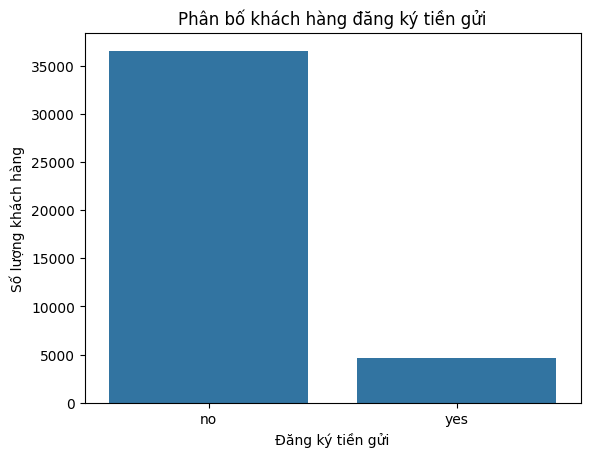

In [3]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Phân bố khách hàng đăng ký tiền gửi")
plt.xlabel("Đăng ký tiền gửi")
plt.ylabel("Số lượng khách hàng")
plt.show()

**Nhận xét:** lớp `no` có 36.548 mẫu (88,73%) còn lớp `yes` chỉ có 4.640 mẫu (11,27%), tức dữ liệu **mất cân bằng nghiêm trọng**. Một mô hình đoán toàn bộ là `no` vẫn đạt Accuracy khoảng 88,7% nhưng không tìm được khách hàng nào đăng ký. Vì vậy đồ án dùng F1-score, Recall và ROC-AUC thay vì chỉ dựa vào Accuracy, đồng thời dùng `class_weight="balanced"` ở các mô hình.

### 3. Tiền xử lý dữ liệu

Các bước thực hiện (theo đúng thứ tự):

1. Loại bản ghi trùng và bản ghi thiếu nhãn.
2. Giữ `unknown` như một nhóm riêng của biến phân loại.
3. Loại cột `duration` để tránh rò rỉ thông tin.
4. Tách đặc trưng `X` và nhãn `y` (`no` thành 0, `yes` thành 1).
5. Chia train/test theo tỷ lệ 80/20 với `stratify=y` và `random_state=42`. Việc chia được thực hiện **trước** khi chuẩn hóa để tránh rò rỉ thông tin từ tập test.
6. Biến số: điền giá trị thiếu bằng trung vị rồi chuẩn hóa `StandardScaler`. Biến phân loại: điền giá trị thiếu bằng giá trị phổ biến nhất rồi mã hóa One-Hot.
7. Các bộ xử lý chỉ `fit` trên tập train, sau đó `transform` cho tập test.

In [ ]:
import sys

sys.path.append("..")  # Để notebook nhìn thấy thư mục src/ ở ngoài
from src.preprocessing import load_and_preprocess_data

X_train, X_test, y_train, y_test, preprocessor = load_and_preprocess_data()
feature_names = preprocessor.get_feature_names_out()

Số dòng sau khi loại trùng/thiếu nhãn: 41176
Số đặc trưng sau mã hóa: 62
Train: X=(32940, 62), y=(32940,)
Test:  X=(8236, 62), y=(8236,)
Tỷ lệ nhãn trong train (%):
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [5]:
import json, os, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

def save_experiment(exp_name, model, params, y_test, y_pred, y_proba, root="results"):
    """Lưu toàn bộ kết quả của một thí nghiệm vào results/<exp_name>/"""
    folder = os.path.join(root, exp_name)
    os.makedirs(folder, exist_ok=True)

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }

    with open(os.path.join(folder, "params_cfg.json"), "w", encoding="utf-8") as f:
        json.dump(params, f, ensure_ascii=False, indent=2, default=str)
    with open(os.path.join(folder, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2)
    pd.DataFrame([metrics]).round(4).to_csv(os.path.join(folder, "metrics.csv"), index=False)
    pd.DataFrame({"y_true": np.asarray(y_test), "y_pred": y_pred, "y_proba": y_proba}).to_csv(
        os.path.join(folder, "predictions.csv"), index=False)
    joblib.dump(model, os.path.join(folder, "best_model.pkl"))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No", "Yes"],
                                            cmap="Blues", ax=axes[0])
    axes[0].set_title(f"{exp_name} - Confusion Matrix")
    RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_title(f"{exp_name} - ROC Curve")
    plt.tight_layout()
    fig.savefig(os.path.join(folder, "confusion_roc.png"), dpi=150)
    plt.close(fig)
    print("Đã lưu vào:", folder)

### 4. Thuật toán Logistic Regression

#### 4.1. Giới thiệu thuật toán

Logistic Regression là thuật toán học có giám sát dùng cho bài toán phân loại. Mô hình tính tổ hợp tuyến tính của các đặc trưng rồi đưa qua hàm sigmoid để ra xác suất khách hàng đăng ký tiền gửi kỳ hạn. Nếu xác suất lớn hơn ngưỡng 0,5 thì dự đoán "yes", ngược lại là "no".

- **Ưu điểm:** đơn giản, huấn luyện nhanh, dễ giải thích qua hệ số của từng đặc trưng.
- **Nhược điểm:** chỉ học được ranh giới phân chia tuyến tính, nhạy với thang đo nên cần dữ liệu đã chuẩn hóa (đã thực hiện ở mục 3).

Cấu hình baseline: `max_iter=2000` để thuật toán hội tụ, `class_weight="balanced"` để tăng trọng số cho lớp "yes" (chỉ chiếm khoảng 11% dữ liệu), `random_state=42` để kết quả lặp lại được.

#### 4.1 Xây dựng mô hình

In [6]:
from sklearn.linear_model import LogisticRegression

# Khởi tạo mô hình Logistic Regression baseline
model_lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Huấn luyện trên tập train
model_lr.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_lr = model_lr.predict(X_test)
y_proba_lr = model_lr.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán Logistic Regression hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_lr[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_lr[:10].round(4))

Huấn luyện và dự đoán Logistic Regression hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]
10 xác suất dự đoán đầu tiên: [0.1848 0.9575 0.3078 0.449  0.3371 0.2638 0.4478 0.3367 0.4135 0.2516]


#### 4.3 Đánh giá mô hình

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, zero_division=0)
recall_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)
auc_lr = roc_auc_score(y_test, y_proba_lr)

# Hiển thị kết quả
print("===== LOGISTIC REGRESSION =====")
print(f"Accuracy : {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall   : {recall_lr:.4f}")
print(f"F1-score : {f1_lr:.4f}")
print(f"ROC-AUC  : {auc_lr:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No", "Yes"],
    zero_division=0
))

===== LOGISTIC REGRESSION =====
Accuracy : 0.8303
Precision: 0.3591
Recall   : 0.6455
F1-score : 0.4615
ROC-AUC  : 0.8002

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



#### 4.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

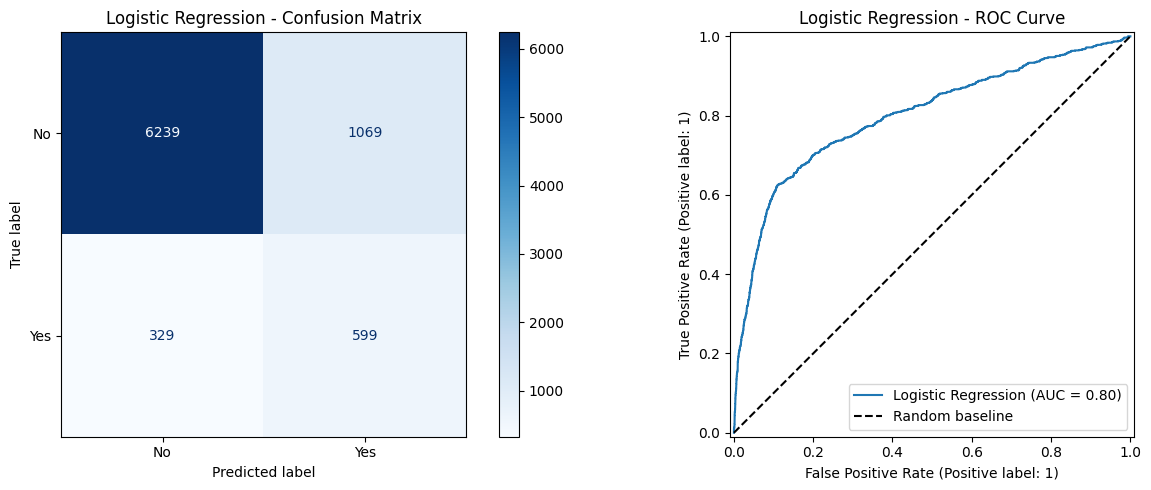

In [8]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_lr,
    name="Logistic Regression",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Logistic Regression - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 4.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Logistic Regression đạt F1-score ≈ 0,46, Recall ≈ 0,65 và ROC-AUC ≈ 0,80 trên tập test. Đây là F1-score và ROC-AUC cao nhất trong 4 mô hình baseline (mục 4 đến 7); Recall tương đương Decision Tree (≈ 0,65) và cao hơn hẳn KNN (≈ 0,31) và Random Forest (≈ 0,28).
- Nhờ `class_weight="balanced"`, mô hình tìm ra khoảng 65% khách hàng thật sự đăng ký (Recall của lớp "yes"). Cái giá phải trả là Precision chỉ khoảng 0,36: trong số khách hàng được dự đoán là "yes", khoảng 64% thực tế không đăng ký, nghĩa là ngân hàng sẽ gọi nhầm khá nhiều khách.
- Accuracy ≈ 0,83 thấp hơn mức 88,7% của một mô hình đoán toàn bộ là "no", nhưng mô hình đó vô dụng vì Recall bằng 0. Điều này cho thấy Accuracy không phù hợp để đánh giá bài toán mất cân bằng và vì sao cần dùng F1-score, Recall, ROC-AUC.
- Hạn chế và hướng cải thiện: mô hình chỉ học được ranh giới tuyến tính; có thể tinh chỉnh tham số `C`, thử chỉnh ngưỡng phân loại để cân bằng giữa Recall và Precision, hoặc thử SMOTE (xem mục 9 và 10).

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [9]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Logistic Regression (baseline)",
    "Accuracy": accuracy_lr,
    "Precision": precision_lr,
    "Recall": recall_lr,
    "F1-score": f1_lr,
    "ROC-AUC": auc_lr
})
all_probas["Logistic Regression (baseline)"] = y_proba_lr

print("Đã lưu kết quả Logistic Regression!")

save_experiment("EXP-01_LogisticRegression_baseline", model_lr, model_lr.get_params(), y_test, y_pred_lr, y_proba_lr)

Đã lưu kết quả Logistic Regression!
Đã lưu vào: results\EXP-01_LogisticRegression_baseline


### 5. Thuật toán K-Nearest Neighbors (KNN)

#### 5.1. Giới thiệu thuật toán

K-Nearest Neighbors (KNN) là thuật toán học máy có giám sát, được sử dụng trong các bài toán phân loại và hồi quy.

Đối với bài toán Bank Marketing, KNN dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không dựa trên nhãn chiếm đa số của K khách hàng gần nhất trong không gian đặc trưng.

- **Ưu điểm:** dễ hiểu, không giả định dạng phân phối của dữ liệu.
- **Nhược điểm:** dự đoán chậm khi dữ liệu lớn, nhạy với thang đo của các đặc trưng (nên cần dữ liệu đã chuẩn hóa ở mục 3) và nhạy với dữ liệu mất cân bằng: lớp "no" chiếm đa số nên các láng giềng gần nhất thường là "no".

Cấu hình baseline: K = 5 và khoảng cách Euclidean. KNN không hỗ trợ `class_weight` nên bản baseline chưa có cơ chế xử lý mất cân bằng lớp.

#### 5.2. Huấn luyện và dự đoán

Với KNN, bước huấn luyện chỉ là lưu lại tập train; việc tìm láng giềng diễn ra khi dự đoán. Sau đó dự đoán nhãn (0: không đăng ký, 1: đăng ký) và xác suất đăng ký trên tập test.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

# Khởi tạo mô hình KNN baseline
model_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

# Huấn luyện trên tập train
model_knn.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_knn = model_knn.predict(X_test)
y_proba_knn = model_knn.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán KNN hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_knn[:10])

Huấn luyện và dự đoán KNN hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]


#### 5.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
auc_knn = roc_auc_score(y_test, y_proba_knn)

# Hiển thị kết quả
print("===== KNN BASELINE =====")
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")
print(f"ROC-AUC  : {auc_knn:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"],
    zero_division=0
))

===== KNN BASELINE =====
Accuracy : 0.8953
Precision: 0.5652
Recall   : 0.3082
F1-score : 0.3989
ROC-AUC  : 0.7400

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



#### 5.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

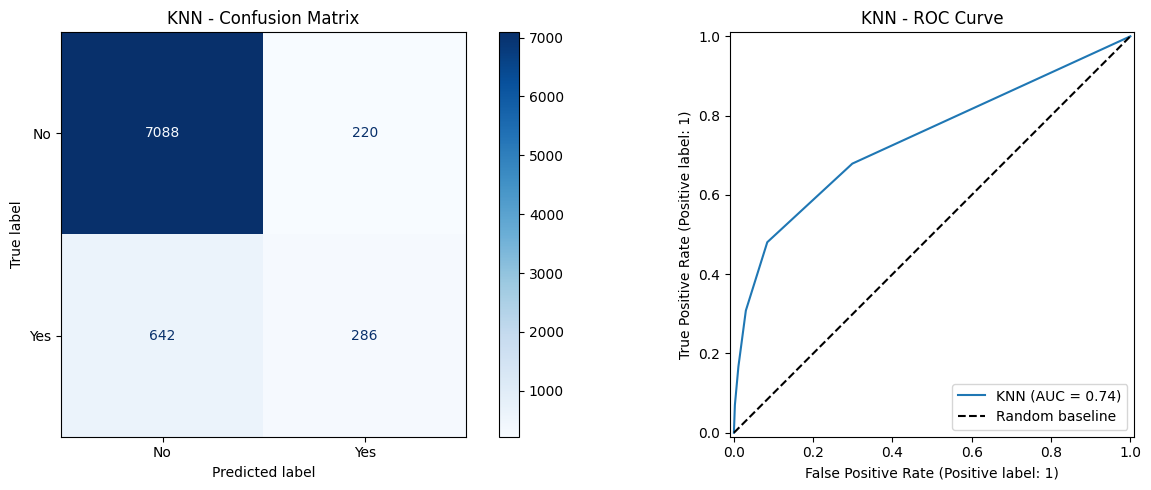

In [12]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("KNN - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_knn,
    name="KNN",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("KNN - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 5.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- KNN đạt F1-score ≈ 0,40, Recall ≈ 0,31 và ROC-AUC ≈ 0,74 trên tập test, thấp hơn Logistic Regression ở cả ba độ đo (F1 ≈ 0,46, Recall ≈ 0,65, ROC-AUC ≈ 0,80).
- Precision của KNN khá cao (≈ 0,57, cao hơn Logistic Regression ≈ 0,36) nhưng Recall thấp: mô hình chỉ tìm ra khoảng 31% khách hàng thật sự đăng ký, bỏ sót khoảng 69%. Mô hình thiên về dự đoán thận trọng, chỉ báo "yes" khi các láng giềng gần đều là "yes".
- Nguyên nhân chính là mất cân bằng lớp: lớp "no" chiếm khoảng 89% nên trong 5 láng giềng gần nhất thường có đa số là "no". Accuracy ≈ 0,90 chỉ nhỉnh hơn mức 88,7% của mô hình đoán toàn bộ là "no", nên không phản ánh đúng chất lượng mô hình.
- Hướng cải thiện: tinh chỉnh `n_neighbors` và `weights="distance"`, thử SMOTE hoặc undersampling, và chỉnh ngưỡng phân loại để tăng Recall (xem mục 9 và 10).

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [13]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "KNN (baseline)",
    "Accuracy": accuracy_knn,
    "Precision": precision_knn,
    "Recall": recall_knn,
    "F1-score": f1_knn,
    "ROC-AUC": auc_knn
})
all_probas["KNN (baseline)"] = y_proba_knn

print("Đã lưu kết quả KNN!")

save_experiment("EXP-02_KNN_baseline", model_knn, model_knn.get_params(), y_test, y_pred_knn, y_proba_knn)

Đã lưu kết quả KNN!
Đã lưu vào: results\EXP-02_KNN_baseline


### 6. Thuật toán Decision Tree

#### 6.1. Giới thiệu thuật toán

Decision Tree là thuật toán học có giám sát chia dữ liệu liên tiếp theo các điều kiện trên đặc trưng (ví dụ `euribor3m < 1,3`) để tạo thành cây quyết định. Mỗi nút lá cho một dự đoán yes hoặc no.

- **Ưu điểm:** dễ hiểu, trực quan, không cần chuẩn hóa dữ liệu, cho biết đặc trưng nào quan trọng.
- **Nhược điểm:** dễ overfitting nếu cây quá sâu, kết quả không ổn định khi dữ liệu thay đổi nhẹ.

Cấu hình baseline: `max_depth=8`, `min_samples_split=20`, `min_samples_leaf=10` để giới hạn độ phức tạp của cây, `class_weight="balanced"` để xử lý mất cân bằng lớp, `random_state=42`.

#### 6.2. Huấn luyện và dự đoán

Huấn luyện mô hình trên tập train, sau đó dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test.

In [14]:
from sklearn.tree import DecisionTreeClassifier

# Khởi tạo mô hình Decision Tree baseline
model_dt = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Huấn luyện trên tập train
model_dt.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
yes_index = list(model_dt.classes_).index(1)
y_pred_dt = model_dt.predict(X_test)
y_proba_dt = model_dt.predict_proba(X_test)[:, yes_index]

print("Huấn luyện và dự đoán Decision Tree hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_dt[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_dt[:10].round(4))

Huấn luyện và dự đoán Decision Tree hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 1 1 0 0 1 0 0 0]
10 xác suất dự đoán đầu tiên: [0.3164 0.9717 0.525  0.525  0.3421 0.2306 0.525  0.2433 0.3421 0.3421]


#### 6.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.#### Dự đoán kết quả

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)
auc_dt = roc_auc_score(y_test, y_proba_dt)

# Hiển thị kết quả
print("===== DECISION TREE BASELINE =====")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1-score : {f1_dt:.4f}")
print(f"ROC-AUC  : {auc_dt:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

===== DECISION TREE BASELINE =====
Accuracy : 0.8263
Precision: 0.3530
Recall   : 0.6509
F1-score : 0.4577
ROC-AUC  : 0.7932

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.35      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



#### 6.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.#### Đánh giá mô hình

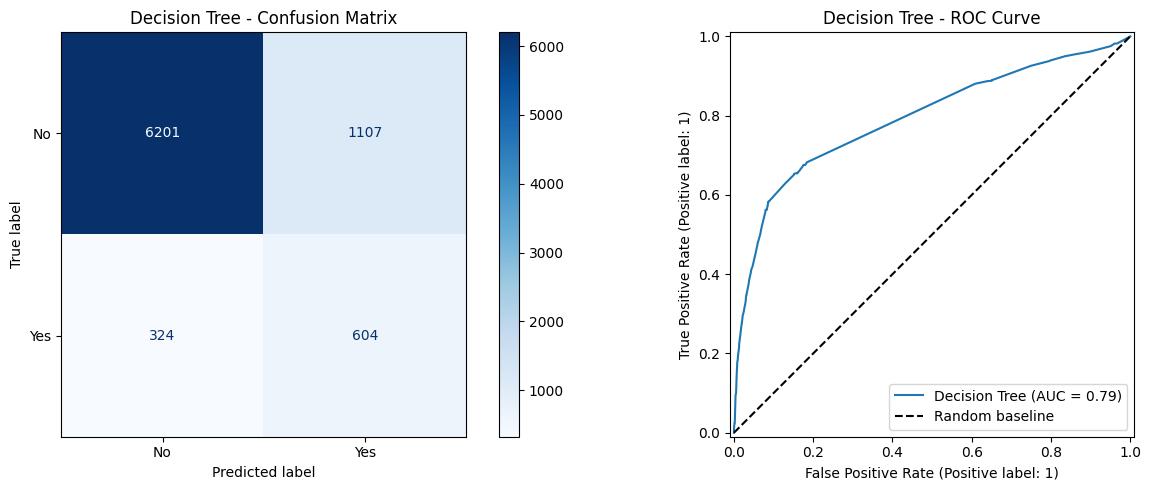

In [16]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_dt,
    name="Decision Tree",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Decision Tree - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 6.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Decision Tree đạt F1-score ≈ 0,46, Recall ≈ 0,65 và ROC-AUC ≈ 0,79 trên tập test, gần tương đương Logistic Regression (F1 ≈ 0,46, Recall ≈ 0,65, ROC-AUC ≈ 0,80) và cao hơn hẳn KNN, Random Forest về Recall.
- Recall cao nhờ `class_weight="balanced"`, đổi lại Precision chỉ khoảng 0,35: khoảng 65% khách hàng được dự đoán là "yes" thực tế không đăng ký. Accuracy ≈ 0,83 thấp hơn mức 88,7% của mô hình đoán toàn bộ là "no", nhưng mô hình đó vô dụng vì Recall bằng 0.
- Việc giới hạn độ sâu (`max_depth=8`) và kích thước nút lá giúp cây tránh overfitting; đây là lý do kết quả tốt hơn nhiều so với cây không giới hạn.
- Hướng cải thiện: tinh chỉnh `max_depth`, `min_samples_leaf` bằng GridSearchCV, và so sánh với Random Forest (xem mục 10). Độ quan trọng của đặc trưng được phân tích ở mục 12.

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [17]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Decision Tree (baseline)",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-score": f1_dt,
    "ROC-AUC": auc_dt
})
all_probas["Decision Tree (baseline)"] = y_proba_dt

print("Đã lưu kết quả Decision Tree!")

save_experiment("EXP-03_DecisionTree_baseline", model_dt, model_dt.get_params(), y_test, y_pred_dt, y_proba_dt)

Đã lưu kết quả Decision Tree!
Đã lưu vào: results\EXP-03_DecisionTree_baseline


### 7. Thuật toán Random Forest

#### 7.1. Giới thiệu thuật toán

Random Forest là thuật toán học có giám sát kết hợp nhiều cây quyết định rồi lấy kết quả bình chọn đa số. Mỗi cây được huấn luyện trên một mẫu ngẫu nhiên (bootstrap) của tập train và chỉ xét một tập con ngẫu nhiên các đặc trưng ở mỗi lần chia nhánh, nên các cây khác nhau và giảm overfitting so với một cây đơn.

- **Ưu điểm:** ổn định, ít overfitting hơn Decision Tree, không cần chuẩn hóa, cho biết độ quan trọng của đặc trưng.
- **Nhược điểm:** khó giải thích hơn một cây đơn, huấn luyện và dự đoán chậm hơn.

Cấu hình baseline: `n_estimators=300` (300 cây), `class_weight="balanced"` để xử lý mất cân bằng lớp, `random_state=42`. Các cây không giới hạn độ sâu.

#### 7.2. Huấn luyện và dự đoán

Huấn luyện mô hình trên tập train, sau đó dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test.

In [18]:
from sklearn.ensemble import RandomForestClassifier

# Khởi tạo mô hình Random Forest baseline
model_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Huấn luyện trên tập train
model_rf.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_rf = model_rf.predict(X_test)
y_proba_rf = model_rf.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán Random Forest hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_rf[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_rf[:10].round(4))

Huấn luyện và dự đoán Random Forest hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]
10 xác suất dự đoán đầu tiên: [0.01   0.7967 0.15   0.2028 0.1633 0.0067 0.0333 0.05   0.0794 0.09  ]


#### 7.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)
auc_rf = roc_auc_score(y_test, y_proba_rf)

# Hiển thị kết quả
print("===== RANDOM FOREST BASELINE =====")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")
print(f"ROC-AUC  : {auc_rf:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

===== RANDOM FOREST BASELINE =====
Accuracy : 0.8930
Precision: 0.5501
Recall   : 0.2780
F1-score : 0.3694
ROC-AUC  : 0.7811

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.91      0.97      0.94      7308
         Yes       0.55      0.28      0.37       928

    accuracy                           0.89      8236
   macro avg       0.73      0.62      0.66      8236
weighted avg       0.87      0.89      0.88      8236



#### 7.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

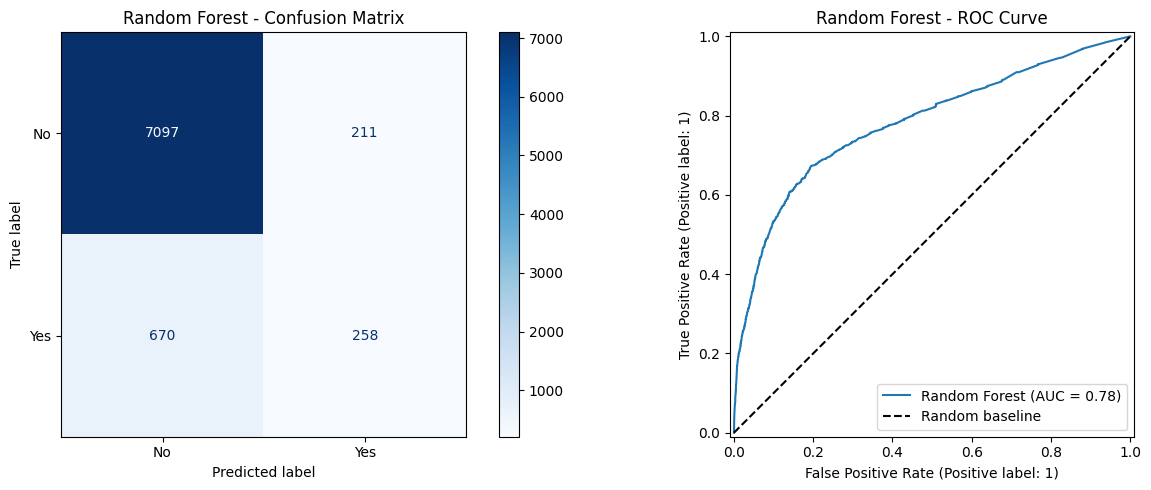

In [20]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Random Forest - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_rf,
    name="Random Forest",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Random Forest - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 7.5. Nhận xét và lưu kết quả

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Random Forest đạt F1-score ≈ 0,37, Recall ≈ 0,28 và ROC-AUC ≈ 0,78 trên tập test. ROC-AUC ở mức khá nhưng thấp hơn Logistic Regression (≈ 0,80) và Decision Tree (≈ 0,79).
- Recall chỉ khoảng 0,28: ở ngưỡng mặc định 0,5 mô hình bỏ sót khoảng 72% khách hàng thật sự đăng ký, thấp hơn nhiều so với Decision Tree và Logistic Regression (≈ 0,65) dù cùng dùng `class_weight="balanced"`. Với ngân hàng, bỏ sót khách tiềm năng là rủi ro đáng kể.
- Một nguyên nhân có thể là các cây không giới hạn độ sâu nên khớp rất sát tập train, khiến xác suất dự đoán cho lớp "yes" hiếm khi vượt ngưỡng 0,5. ROC-AUC khá cho thấy mô hình vẫn xếp hạng khách hàng tương đối tốt, vấn đề chủ yếu nằm ở ngưỡng phân loại.
- Hướng cải thiện: giới hạn `max_depth`, tăng `min_samples_leaf`, chỉnh `max_features`, hạ ngưỡng phân loại và thử SMOTE (xem mục 9 và 10). Độ quan trọng của đặc trưng được phân tích ở mục 12.

Kết quả được lưu vào danh sách chung `all_results` để so sánh với các mô hình khác ở mục 8.

In [21]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "Random Forest (baseline)",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-score": f1_rf,
    "ROC-AUC": auc_rf
})
all_probas["Random Forest (baseline)"] = y_proba_rf

print("Đã lưu kết quả Random Forest!")

save_experiment("EXP-04_RandomForest_baseline", model_rf, model_rf.get_params(), y_test, y_pred_rf, y_proba_rf)

Đã lưu kết quả Random Forest!
Đã lưu vào: results\EXP-04_RandomForest_baseline


### 8. So sánh 4 mô hình baseline

Tổng hợp kết quả của 4 mô hình ở mục 4 đến 7 (đã lưu trong `all_results` và `all_probas`), tất cả cùng dùng một tập train/test. Cần chạy xong các mục 4 đến 7 trước khi chạy mục này.

#### 8.1. Bảng so sánh

In [22]:
import pandas as pd

assert len(all_results) > 0, "Chưa có kết quả: hãy chạy các mục 4 đến 7 trước."

# Bảng kết quả của các mô hình baseline (bỏ dòng trùng nếu chạy lại ô)
df_results = pd.DataFrame(all_results)
df_results = df_results.drop_duplicates(subset="Model", keep="last")
df_results = df_results[df_results["Model"].str.endswith("(baseline)")]
df_results = df_results.sort_values(by="F1-score", ascending=False).reset_index(drop=True)

display(df_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (baseline),0.8303,0.3591,0.6455,0.4615,0.8002
1,Decision Tree (baseline),0.8263,0.3530,0.6509,0.4577,0.7932
2,KNN (baseline),0.8953,0.5652,0.3082,0.3989,0.7400
3,Random Forest (baseline),0.8930,0.5501,0.2780,0.3694,0.7811


#### 8.2. Biểu đồ so sánh F1-score, Recall và ROC-AUC

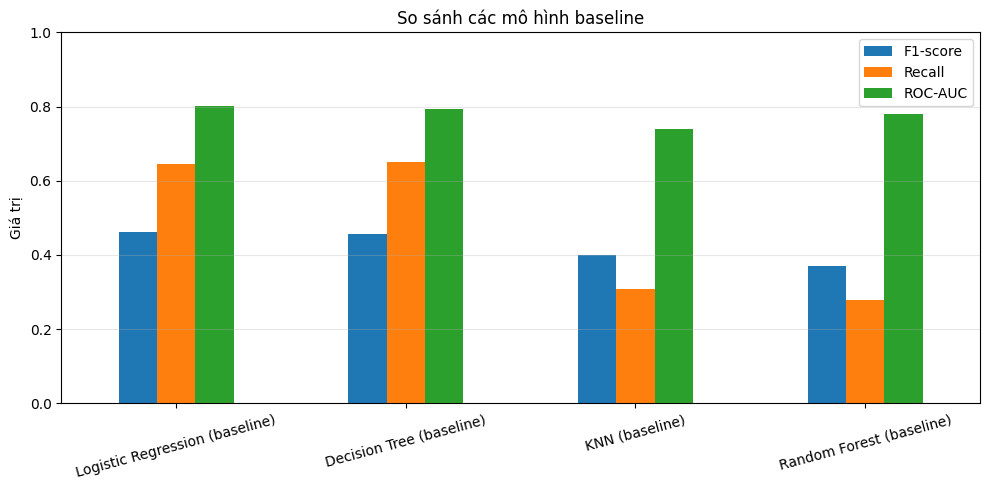

In [23]:
import matplotlib.pyplot as plt

metrics = ["F1-score", "Recall", "ROC-AUC"]
ax = df_results.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 5))

ax.set_title("So sánh các mô hình baseline")
ax.set_ylabel("Giá trị")
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### 8.3. ROC Curve của các mô hình

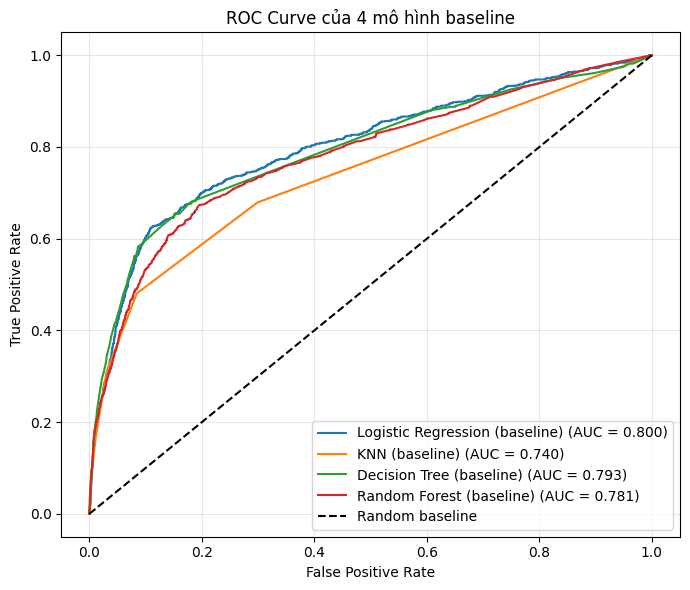

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 6))

for name, proba in all_probas.items():
    if not name.endswith("(baseline)"):
        continue
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve của 4 mô hình baseline")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 8.4. Nhận xét

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- **Logistic Regression** có F1-score (≈ 0,46) và ROC-AUC (≈ 0,80) cao nhất. **Decision Tree** (đã giới hạn độ sâu) sát ngay phía sau (F1 ≈ 0,46, ROC-AUC ≈ 0,79) và có Recall nhỉnh hơn (≈ 0,65).
- **KNN** và **Random Forest** có Recall thấp (≈ 0,31 và ≈ 0,28), nghĩa là bỏ sót phần lớn khách hàng thật sự đăng ký ở ngưỡng 0,5. Riêng Random Forest vẫn có ROC-AUC khá (≈ 0,78), cho thấy mô hình xếp hạng khách hàng tương đối tốt và vấn đề chủ yếu nằm ở ngưỡng phân loại.
- Các mô hình dùng `class_weight="balanced"` (Logistic Regression, Decision Tree) đạt Recall cao hơn hẳn KNN, vốn chưa có cơ chế xử lý mất cân bằng lớp.
- Đây mới là kết quả baseline với tham số ban đầu. Nửa sau của đồ án sẽ thử xử lý mất cân bằng, chỉnh ngưỡng và tinh chỉnh siêu tham số (mục 9 đến 11) để cải thiện Recall và F1-score.

### 9. Xử lý mất cân bằng lớp và chỉnh ngưỡng


### 9.2 KNN

In [25]:
##%pip install imbalanced-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


def knn_metrics(y_true, y_pred, y_proba):
    """Đánh giá với lớp yes = 1 là lớp dương."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }


def knn_save_result(name, metrics, proba):
    """Lưu vào kết quả chung; thay kết quả cũ nếu chạy lại cell."""
    global all_results, all_probas

    if "all_results" not in globals():
        all_results = []
    if "all_probas" not in globals():
        all_probas = {}

    all_results[:] = [
        row for row in all_results if row["Model"] != name
    ]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = proba


def knn_report(name, y_pred, y_proba):
    """In độ đo, vẽ biểu đồ và lưu kết quả."""
    metrics = knn_metrics(y_test, y_pred, y_proba)

    print(f"===== {name.upper()} =====")
    for metric, value in metrics.items():
        print(f"{metric:<10}: {value:.4f}")

    print("\n===== CLASSIFICATION REPORT =====")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No", "Yes"],
        zero_division=0,
    ))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=axes[0],
    )
    axes[0].set_title(f"{name} - Confusion Matrix")

    RocCurveDisplay.from_predictions(
        y_test,
        y_proba,
        name=name,
        ax=axes[1],
    )
    axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
    axes[1].set_title(f"{name} - ROC Curve")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

    knn_save_result(name, metrics, y_proba)
    return metrics

In [26]:
required_variables = [
    "preprocessor",
    "X_train_raw",
    "X_test_raw",
    "y_train",
    "y_test",
    "model_knn",
    "knn_report",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    print("Các biến/hàm chưa có:", ", ".join(missing_variables))
    print("Hãy chạy lại các cell tạo chúng ở phía trên.")
else:
    print("Đã đủ biến và hàm. Có thể chạy cell KNN + SMOTE.")

Đã đủ biến và hàm. Có thể chạy cell KNN + SMOTE.


#### 9.2.1 Cân bằng dữ liệu bằng SMOTE

In [27]:
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score

X_knn_smote, y_knn_smote = SMOTE(
    random_state=42
).fit_resample(X_train, y_train)

model_knn_smote = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)
model_knn_smote.fit(X_knn_smote, y_knn_smote)

y_pred_knn_smote = model_knn_smote.predict(X_test)
y_proba_knn_smote = model_knn_smote.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, y_pred_knn_smote,
    target_names=["No", "Yes"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_knn_smote), 4))

save_experiment("EXP-06_KNN_SMOTE", model_knn_smote, model_knn_smote.get_params(), y_test, y_pred_knn_smote, y_proba_knn_smote)

              precision    recall  f1-score   support

          No       0.94      0.75      0.84      7308
         Yes       0.25      0.63      0.35       928

    accuracy                           0.74      8236
   macro avg       0.59      0.69      0.60      8236
weighted avg       0.86      0.74      0.78      8236

ROC-AUC: 0.7321
Đã lưu vào: results\EXP-06_KNN_SMOTE


#### 9.2.2. Chỉnh ngưỡng phân loại

,Threshold,Precision,Recall,F1-score
0,0.0,0.1127,1.0000,0.2025
1,0.2,0.2179,0.6607,0.3277
2,0.4,0.3965,0.4492,0.4212
3,0.6,0.5350,0.2948,0.3801
4,0.8,0.6422,0.1558,0.2507
5,1.0,0.7094,0.0507,0.0946


Ngưỡng được chọn trên train: 0.4000
F1 OOF tại ngưỡng này: 0.4212


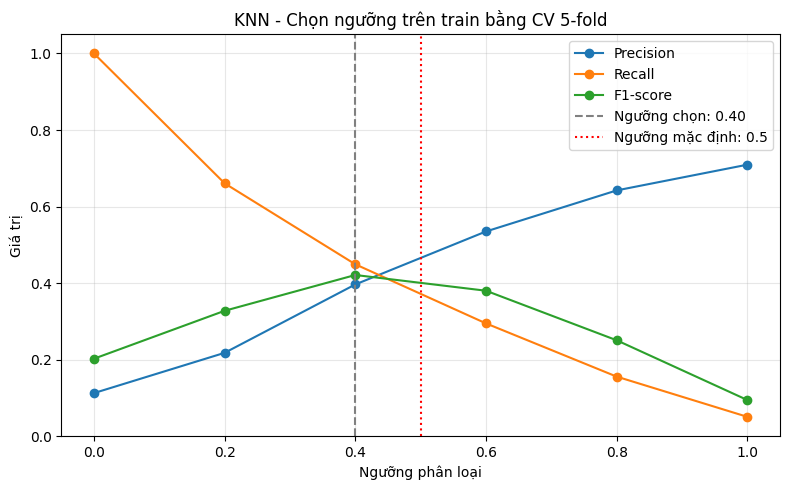

===== KNN (THRESHOLD) =====
Accuracy  : 0.8668
Precision : 0.4204
Recall    : 0.4806
F1-score  : 0.4485
ROC-AUC   : 0.7400

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.93      0.92      0.92      7308
         Yes       0.42      0.48      0.45       928

    accuracy                           0.87      8236
   macro avg       0.68      0.70      0.69      8236
weighted avg       0.88      0.87      0.87      8236



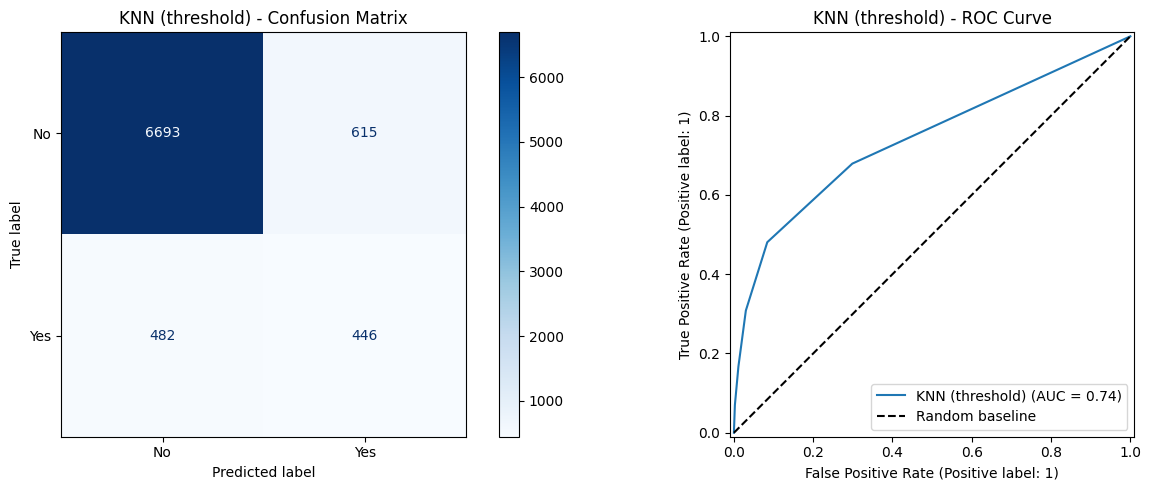

In [ ]:
cv_knn_threshold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

knn_threshold_pipeline = SkPipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("knn", clone(model_knn).set_params(n_jobs=1)),
    ]
)

# Mỗi mẫu train được dự đoán bởi mô hình chưa học mẫu đó.
oof_proba_knn = cross_val_predict(
    knn_threshold_pipeline,
    X_train_raw,
    y_train,
    cv=cv_knn_threshold,
    method="predict_proba",
    n_jobs=2,
)[:, 1]

# Xét các ngưỡng tương ứng với xác suất OOF thực tế.
precision_oof, recall_oof, thresholds_knn = precision_recall_curve(
    y_train,
    oof_proba_knn,
)

# Phần tử cuối của precision/recall không có ngưỡng tương ứng.
f1_oof = np.divide(
    2 * precision_oof[:-1] * recall_oof[:-1],
    precision_oof[:-1] + recall_oof[:-1],
    out=np.zeros_like(precision_oof[:-1]),
    where=(precision_oof[:-1] + recall_oof[:-1]) > 0,
)

df_thr_knn = pd.DataFrame({
    "Threshold": thresholds_knn,
    "Precision": precision_oof[:-1],
    "Recall": recall_oof[:-1],
    "F1-score": f1_oof,
})

best_idx_knn = df_thr_knn["F1-score"].idxmax()
best_threshold_knn = float(
    df_thr_knn.loc[best_idx_knn, "Threshold"]
)

display(df_thr_knn.round(4))
print(f"Ngưỡng được chọn trên train: {best_threshold_knn:.4f}")
print(f"F1 OOF tại ngưỡng này: {f1_oof[best_idx_knn]:.4f}")

plt.figure(figsize=(8, 5))

for metric in ["Precision", "Recall", "F1-score"]:
    plt.plot(
        df_thr_knn["Threshold"],
        df_thr_knn[metric],
        marker="o",
        label=metric,
    )

plt.axvline(
    best_threshold_knn,
    color="gray",
    linestyle="--",
    label=f"Ngưỡng chọn: {best_threshold_knn:.2f}",
)
plt.axvline(
    0.5,
    color="red",
    linestyle=":",
    label="Ngưỡng mặc định: 0.5",
)

plt.title("KNN - Chọn ngưỡng trên train bằng CV 5-fold")
plt.xlabel("Ngưỡng phân loại")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Dùng xác suất baseline đã có từ mục 5.
y_pred_knn_thr = (
    y_proba_knn >= best_threshold_knn
).astype(int)

metrics_knn_thr = knn_report(
    "KNN (threshold)",
    y_pred_knn_thr,
    y_proba_knn,
)

save_experiment("EXP-10_KNN_threshold", model_knn, {**model_knn.get_params(), "threshold": best_threshold_knn}, y_test, y_pred_knn_thr, y_proba_knn)

#### 9.2.3. So sánh với baseline

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (baseline),0.8953,0.5652,0.3082,0.3989,0.7400
KNN (SMOTE),0.7394,0.2454,0.6325,0.3536,0.7321
KNN (threshold),0.8668,0.4204,0.4806,0.4485,0.7400


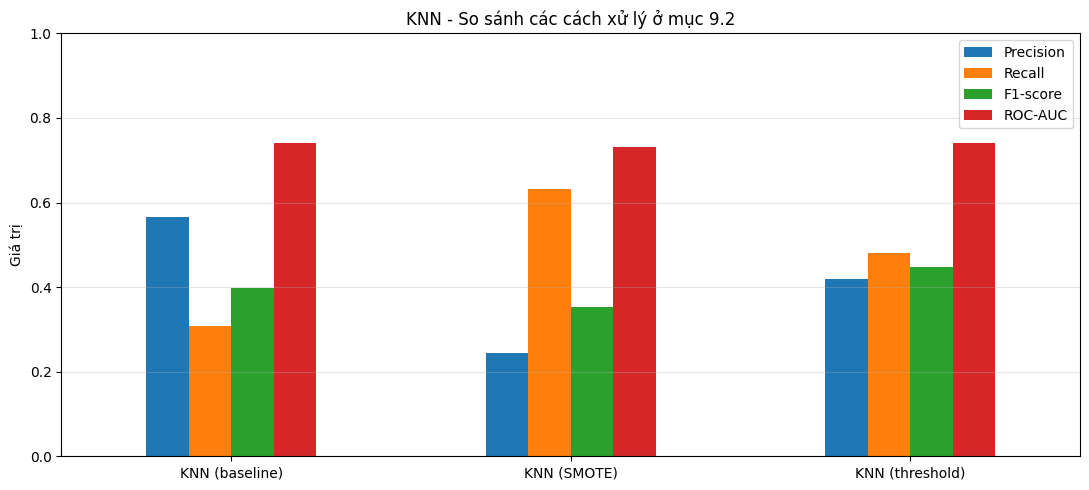


KNN (SMOTE) so với baseline:
  Chênh lệch Precision: -0.3198
  Chênh lệch Recall: +0.3244
  Chênh lệch F1-score: -0.0453
  Chênh lệch ROC-AUC: -0.0079

KNN (threshold) so với baseline:
  Chênh lệch Precision: -0.1449
  Chênh lệch Recall: +0.1724
  Chênh lệch F1-score: +0.0496
  Chênh lệch ROC-AUC: +0.0000


In [29]:
metrics_knn_smote = knn_metrics(
    y_test, y_pred_knn_smote, y_proba_knn_smote
)

metrics_knn_thr = knn_metrics(
    y_test, y_pred_knn_thr, y_proba_knn
)
metrics_knn_baseline = knn_metrics(
    y_test,
    y_pred_knn,
    y_proba_knn,
)

df_knn_section9 = pd.DataFrame([
    {"Model": "KNN (baseline)", **metrics_knn_baseline},
    {"Model": "KNN (SMOTE)", **metrics_knn_smote},
    {"Model": "KNN (threshold)", **metrics_knn_thr},
]).set_index("Model")

display(df_knn_section9.round(4))

df_knn_section9[["Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0,
)

plt.title("KNN - So sánh các cách xử lý ở mục 9.2")
plt.xlabel("")
plt.ylabel("Giá trị")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for name in ["KNN (SMOTE)", "KNN (threshold)"]:
    delta = (
        df_knn_section9.loc[name]
        - df_knn_section9.loc["KNN (baseline)"]
    )
    print(f"\n{name} so với baseline:")
    for metric in ["Precision", "Recall", "F1-score", "ROC-AUC"]:
        print(f"  Chênh lệch {metric}: {delta[metric]:+.4f}")

#### 9.4. Random Forest

##### 9.4.1. Cân bằng dữ liệu bằng SMOTE

SMOTE sinh thêm các mẫu `yes` nhân tạo bằng cách nội suy giữa các mẫu `yes` gần nhau, đến khi hai lớp có số lượng bằng nhau. Chỉ áp dụng trên **tập train**, tập test giữ nguyên để đánh giá đúng thực tế. Vì dữ liệu train sau khi sinh đã cân bằng nên mô hình dùng `class_weight=None` để không bù trừ hai lần.

Lưu ý hạn chế: dữ liệu đã One-Hot nên các mẫu nhân tạo có thể chứa giá trị thập phân ở các cột nhị phân.

In [28]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

def rf_metrics(y_true, y_pred, y_proba):
    """Tính 5 độ đo cho một phiên bản mô hình."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

def save_result(name, metrics, proba):
    """Lưu kết quả vào danh sách chung (thay dòng cũ nếu chạy lại)."""
    global all_results, all_probas
    if "all_results" not in globals():
        all_results = []
    if "all_probas" not in globals():
        all_probas = {}
    all_results[:] = [r for r in all_results if r["Model"] != name]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = proba

from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# Cân bằng lại tập train (không đụng tới tập test)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Phân bố lớp trước SMOTE:", dict(pd.Series(y_train).value_counts()))
print("Phân bố lớp sau SMOTE :", dict(pd.Series(y_train_smote).value_counts()))

# Huấn luyện Random Forest trên dữ liệu đã cân bằng
model_rf_smote = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
model_rf_smote.fit(X_train_smote, y_train_smote)

# Dự đoán và đánh giá trên tập test gốc
y_pred_rf_smote = model_rf_smote.predict(X_test)
y_proba_rf_smote = model_rf_smote.predict_proba(X_test)[:, 1]

metrics_rf_smote = rf_metrics(y_test, y_pred_rf_smote, y_proba_rf_smote)

print("\n===== RANDOM FOREST + SMOTE =====")
for k, v in metrics_rf_smote.items():
    print(f"{k:<10}: {v:.4f}")

# Lưu kết quả vào danh sách chung
save_result("Random Forest (SMOTE)", metrics_rf_smote, y_proba_rf_smote)

save_experiment("EXP-08_RandomForest_SMOTE", model_rf_smote, model_rf_smote.get_params(), y_test, y_pred_rf_smote, y_proba_rf_smote)

Phân bố lớp trước SMOTE: {0: np.int64(29229), 1: np.int64(3711)}
Phân bố lớp sau SMOTE : {0: np.int64(29229), 1: np.int64(29229)}

===== RANDOM FOREST + SMOTE =====
Accuracy  : 0.8862
Precision : 0.4931
Recall    : 0.3481
F1-score  : 0.4081
ROC-AUC   : 0.7793
Đã lưu vào: results\EXP-08_RandomForest_SMOTE


##### 9.4.2. Chỉnh ngưỡng phân loại

Mặc định mô hình dự đoán `yes` khi xác suất ≥ 0,5. Hạ ngưỡng xuống sẽ bắt được nhiều khách hàng đăng ký hơn (Recall tăng) nhưng gọi nhầm nhiều hơn (Precision giảm).

Để tránh rò rỉ thông tin, ngưỡng được **chọn trên tập train** bằng xác suất dự đoán chéo (cross-validation 5-fold, mỗi mẫu được dự đoán bởi mô hình chưa từng thấy nó), chọn ngưỡng cho F1-score cao nhất. Sau đó mới áp dụng ngưỡng đó lên tập test, không dùng tập test để chọn ngưỡng.

,Threshold,Precision,Recall,F1-score
0,0.05,0.1916,0.7766,0.3073
1,0.10,0.2697,0.6769,0.3857
2,0.15,0.3289,0.6130,0.4282
3,0.20,0.3740,0.5662,0.4504
4,0.25,0.4093,0.5125,0.4551
5,0.30,0.4416,0.4662,0.4535
6,0.35,0.4718,0.4188,0.4437
7,0.40,0.4939,0.3684,0.4220
8,0.45,0.5227,0.3223,0.3987
9,0.50,0.5432,0.2781,0.3678


Ngưỡng được chọn (F1 cao nhất trên train): 0.25


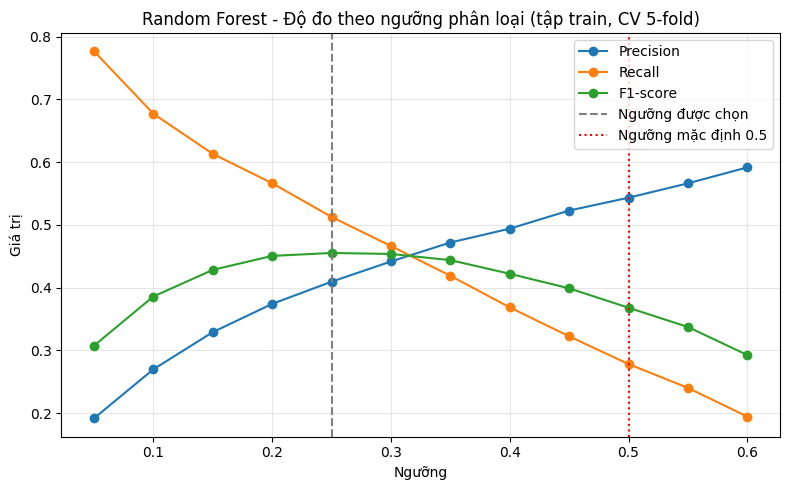

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Xác suất dự đoán chéo trên tập train bằng mô hình baseline
oof_proba_rf = cross_val_predict(
    clone(model_rf), X_train, y_train,
    cv=skf, method="predict_proba"
)[:, 1]

# Quét ngưỡng từ 0.05 đến 0.60
thresholds = np.arange(0.05, 0.65, 0.05)
rows = []
for t in thresholds:
    pred = (oof_proba_rf >= t).astype(int)
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1-score": f1_score(y_train, pred, zero_division=0),
    })

df_thr_rf = pd.DataFrame(rows)
display(df_thr_rf.round(4))

# Chọn ngưỡng có F1-score cao nhất trên tập train
best_threshold_rf = df_thr_rf.loc[df_thr_rf["F1-score"].idxmax(), "Threshold"]
print(f"Ngưỡng được chọn (F1 cao nhất trên train): {best_threshold_rf}")

# Biểu đồ Precision, Recall, F1 theo ngưỡng
plt.figure(figsize=(8, 5))
for col in ["Precision", "Recall", "F1-score"]:
    plt.plot(df_thr_rf["Threshold"], df_thr_rf[col], marker="o", label=col)
plt.axvline(best_threshold_rf, color="gray", linestyle="--", label="Ngưỡng được chọn")
plt.axvline(0.5, color="red", linestyle=":", label="Ngưỡng mặc định 0.5")
plt.title("Random Forest - Độ đo theo ngưỡng phân loại (tập train, CV 5-fold)")
plt.xlabel("Ngưỡng")
plt.ylabel("Giá trị")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

===== RANDOM FOREST + NGƯỠNG 0.25 =====
Accuracy  : 0.8618
Precision : 0.4101
Recall    : 0.5162
F1-score  : 0.4571
ROC-AUC   : 0.7811


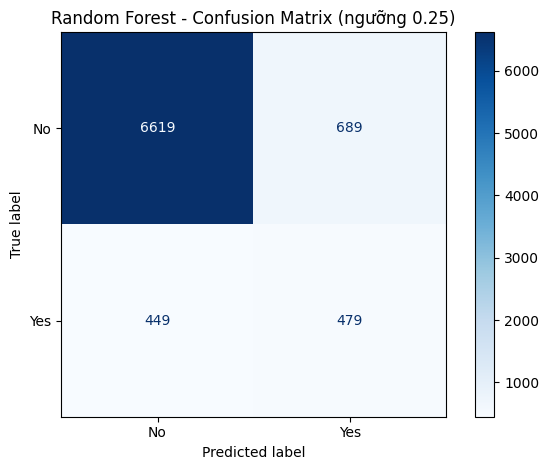

Đã lưu vào: results\EXP-12_RandomForest_threshold


In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

# Áp dụng ngưỡng đã chọn lên tập test (xác suất của mô hình baseline y_proba_rf)
y_pred_rf_thr = (y_proba_rf >= best_threshold_rf).astype(int)

metrics_rf_thr = rf_metrics(y_test, y_pred_rf_thr, y_proba_rf)

print(f"===== RANDOM FOREST + NGƯỠNG {best_threshold_rf} =====")
for k, v in metrics_rf_thr.items():
    print(f"{k:<10}: {v:.4f}")

# Confusion Matrix với ngưỡng mới
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf_thr,
    display_labels=["No", "Yes"], cmap="Blues"
)
plt.title(f"Random Forest - Confusion Matrix (ngưỡng {best_threshold_rf})")
plt.tight_layout()
plt.show()

# Lưu kết quả vào danh sách chung (ROC-AUC không đổi vì cùng xác suất)
save_result("Random Forest (threshold)", metrics_rf_thr, y_proba_rf)

save_experiment("EXP-12_RandomForest_threshold", model_rf, {**model_rf.get_params(), "threshold": float(best_threshold_rf)}, y_test, y_pred_rf_thr, y_proba_rf)

##### 9.4.3. Nhận xét

**Nhận xét (điền sau khi chạy, bám sát số liệu thật):**

- Baseline: Recall = ..., F1-score = ... (xem mục 7).
- SMOTE: Recall = ..., Precision = ..., F1-score = ... So với baseline, Recall (tăng/giảm) ..., ROC-AUC (tăng/giảm) ...
- Chỉnh ngưỡng: ngưỡng được chọn = ..., Recall = ..., Precision = ..., F1-score = ... Ngưỡng thấp hơn 0,5 giúp ... nhưng đổi lại ...
- Cách nào cải thiện F1-score và Recall tốt hơn? Ý nghĩa với ngân hàng: ... (ví dụ chấp nhận gọi nhầm thêm khách để không bỏ sót khách tiềm năng).

### 10. Tinh chỉnh siêu tham số

_Nội dung sẽ được bổ sung._

### 10.2. KNN
Ở đây tinh chỉnh KNN trên train gốc, dùng ngưỡng mặc định, để so sánh riêng tác động của siêu tham số. Các tham số gồm số láng giềng, cách bỏ phiếu và khoảng cách Manhattan/Euclidean.

#### 10.2.1. Tìm kiếm siêu tham số

In [33]:
import time

pipeline_knn_tuning = SkPipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("knn", KNeighborsClassifier(
            metric="minkowski",
            n_jobs=1,
        )),
    ]
)

# p=1: Manhattan; p=2: Euclidean.
param_grid_knn = {
    "knn__n_neighbors": [3, 5, 11, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

cv_knn_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

search_knn = GridSearchCV(
    estimator=pipeline_knn_tuning,
    param_grid=param_grid_knn,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc",
    },
    refit="f1",
    cv=cv_knn_tuning,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    error_score="raise",
)

start_knn = time.perf_counter()

# Pipeline fit tiền xử lý riêng trong từng fold.
search_knn.fit(X_train_raw, y_train)

elapsed_knn = time.perf_counter() - start_knn

print(f"\nThời gian tìm kiếm: {elapsed_knn / 60:.2f} phút")
print("Tham số tốt nhất:", search_knn.best_params_)
print(f"F1-score CV tốt nhất: {search_knn.best_score_:.4f}")

cv_results_knn = pd.DataFrame(search_knn.cv_results_)

cols_knn = [
    "rank_test_f1",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_recall",
    "mean_test_roc_auc",
    "params",
]

display(
    cv_results_knn
    .sort_values("rank_test_f1")[cols_knn]
    .head(10)
    .reset_index(drop=True)
    .round(4)
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits



Thời gian tìm kiếm: 23.72 phút
Tham số tốt nhất: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
F1-score CV tốt nhất: 0.3799


,rank_test_f1,mean_test_f1,std_test_f1,mean_test_recall,mean_test_roc_auc,params
0,1,0.3799,0.0131,0.2948,0.7252,"{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__wei..."
1,2,0.3730,0.0108,0.2905,0.7258,"{'knn__n_neighbors': 5, 'knn__p': 1, 'knn__wei..."
2,3,0.3722,0.0149,0.3024,0.7214,"{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__wei..."
3,4,0.3679,0.0179,0.3013,0.6999,"{'knn__n_neighbors': 3, 'knn__p': 2, 'knn__wei..."
4,5,0.3648,0.0141,0.2762,0.7455,"{'knn__n_neighbors': 11, 'knn__p': 2, 'knn__we..."
5,6,0.3644,0.0199,0.2994,0.6990,"{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__wei..."
6,7,0.3623,0.0115,0.2630,0.7513,"{'knn__n_neighbors': 11, 'knn__p': 2, 'knn__we..."
7,8,0.3612,0.0153,0.2972,0.7212,"{'knn__n_neighbors': 5, 'knn__p': 1, 'knn__wei..."
8,9,0.3603,0.0183,0.3104,0.6982,"{'knn__n_neighbors': 3, 'knn__p': 2, 'knn__wei..."
9,10,0.3600,0.0125,0.2749,0.7449,"{'knn__n_neighbors': 11, 'knn__p': 1, 'knn__we..."


#### 10.2.2. Đánh giá mô hình sau tinh chỉnh

===== KNN (TUNED) =====
Accuracy  : 0.8953
Precision : 0.5652
Recall    : 0.3082
F1-score  : 0.3989
ROC-AUC   : 0.7400

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



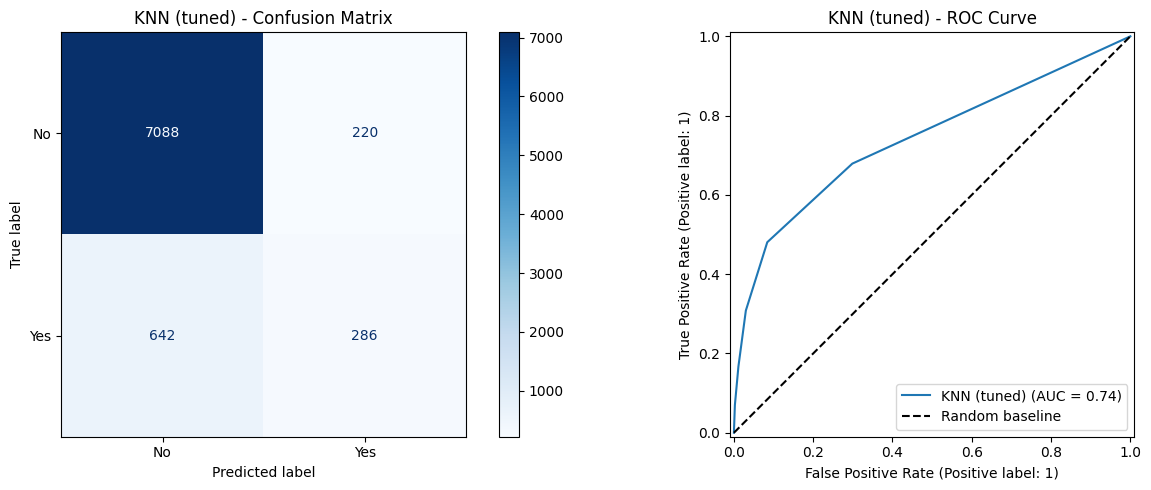

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (baseline),0.8953,0.5652,0.3082,0.3989,0.7400
KNN (SMOTE),0.7394,0.2454,0.6325,0.3536,0.7321
KNN (threshold),0.8668,0.4204,0.4806,0.4485,0.7400
KNN (tuned),0.8953,0.5652,0.3082,0.3989,0.7400


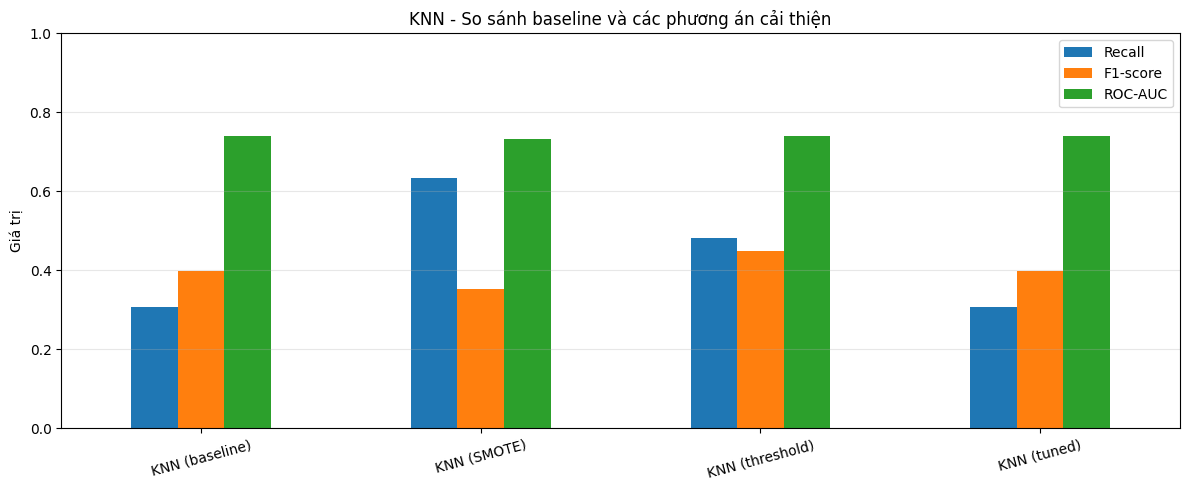


Tham số KNN tốt nhất:
{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}

Chênh lệch sau tinh chỉnh so với baseline:
Accuracy  : +0.0000
Precision : +0.0000
Recall    : +0.0000
F1-score  : +0.0000
ROC-AUC   : +0.0000


In [ ]:
# GridSearchCV đã refit mô hình tốt nhất trên toàn bộ train.
model_knn_tuned = search_knn.best_estimator_

y_pred_knn_tuned = model_knn_tuned.predict(X_test_raw)
y_proba_knn_tuned = model_knn_tuned.predict_proba(X_test_raw)[:, 1]

metrics_knn_tuned = knn_report(
    "KNN (tuned)",
    y_pred_knn_tuned,
    y_proba_knn_tuned,
)

# So sánh cả bốn phiên bản KNN.
df_knn_compare = pd.DataFrame([
    {"Model": "KNN (baseline)", **metrics_knn_baseline},
    {"Model": "KNN (SMOTE)", **metrics_knn_smote},
    {"Model": "KNN (threshold)", **metrics_knn_thr},
    {"Model": "KNN (tuned)", **metrics_knn_tuned},
]).set_index("Model")

display(df_knn_compare.round(4))

df_knn_compare[["Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(12, 5),
    ylim=(0, 1),
    rot=15,
)

plt.title("KNN - So sánh baseline và các phương án cải thiện")
plt.xlabel("")
plt.ylabel("Giá trị")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTham số KNN tốt nhất:")
print(search_knn.best_params_)

print("\nChênh lệch sau tinh chỉnh so với baseline:")
for metric in metrics_knn_baseline:
    difference = (
        metrics_knn_tuned[metric] - metrics_knn_baseline[metric]
    )
    print(f"{metric:<10}: {difference:+.4f}")

save_experiment("EXP-14_KNN_tuned", model_knn_tuned, search_knn.best_params_, y_test, y_pred_knn_tuned, y_proba_knn_tuned)

#### 10.4. Random Forest 

##### 10.4.1. Tìm kiếm siêu tham số

Dùng `RandomizedSearchCV` (thử 20 tổ hợp ngẫu nhiên, chạy nhanh hơn GridSearchCV nhiều với không gian tìm kiếm lớn), chia dữ liệu bằng Stratified 5-fold. Tối ưu theo **F1-score** (độ đo chính), đồng thời ghi lại ROC-AUC. Các tham số tìm kiếm:

| Tham số | Giá trị thử | Ý nghĩa |
|---|---|---|
| `n_estimators` | 200, 300, 500 | Số cây |
| `max_depth` | 6, 8, 10, 12, 15, không giới hạn | Độ sâu tối đa, giới hạn để tránh overfitting |
| `min_samples_leaf` | 1, 3, 5, 10, 20 | Số mẫu tối thiểu ở nút lá |
| `min_samples_split` | 2, 10, 20 | Số mẫu tối thiểu để chia nút |
| `max_features` | `sqrt`, `log2`, 0.3 | Số đặc trưng xét ở mỗi lần chia |
| `class_weight` | `balanced`, `balanced_subsample` | Cách tăng trọng số lớp `yes` |

In [31]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Không gian tìm kiếm
param_dist_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8, 10, 12, 15, None],
    "min_samples_leaf": [1, 3, 5, 10, 20],
    "min_samples_split": [2, 10, 20],
    "max_features": ["sqrt", "log2", 0.3],
    "class_weight": ["balanced", "balanced_subsample"],
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# n_jobs=1 cho mô hình, song song hóa ở mức RandomizedSearchCV
search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring={"f1": "f1", "roc_auc": "roc_auc"},
    refit="f1",
    cv=skf,
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

start = time.time()
search_rf.fit(X_train, y_train)
print(f"Thời gian tìm kiếm: {(time.time() - start) / 60:.1f} phút")

print("\nTham số tốt nhất:")
for k, v in search_rf.best_params_.items():
    print(f"  {k}: {v}")
print(f"F1-score CV tốt nhất: {search_rf.best_score_:.4f}")

# Top 5 tổ hợp tốt nhất
cv_rf = pd.DataFrame(search_rf.cv_results_)
cols = ["rank_test_f1", "mean_test_f1", "mean_test_roc_auc", "params"]
display(cv_rf.sort_values("rank_test_f1")[cols].head(5).round(4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\Chau\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Thời gian tìm kiếm: 34.4 phút

Tham số tốt nhất:
  n_estimators: 200
  min_samples_split: 10
  min_samples_leaf: 3
  max_features: sqrt
  max_depth: 15
  class_weight: balanced
F1-score CV tốt nhất: 0.4953


,rank_test_f1,mean_test_f1,mean_test_roc_auc,params
14,1,0.4953,0.7984,"{'n_estimators': 200, 'min_samples_split': 10,..."
4,2,0.4941,0.7925,"{'n_estimators': 200, 'min_samples_split': 20,..."
16,3,0.4917,0.7997,"{'n_estimators': 500, 'min_samples_split': 2, ..."
6,4,0.4904,0.7891,"{'n_estimators': 500, 'min_samples_split': 10,..."
3,5,0.4872,0.7993,"{'n_estimators': 200, 'min_samples_split': 2, ..."


##### 10.4.2. Đánh giá mô hình sau tinh chỉnh

Dùng mô hình tốt nhất tìm được (đã huấn luyện lại trên toàn bộ tập train) để dự đoán và đánh giá trên tập test.

===== RANDOM FOREST (TUNED) =====
Accuracy  : 0.8729
Precision : 0.4528
Recall    : 0.6153
F1-score  : 0.5217
ROC-AUC   : 0.8120

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.95      0.91      0.93      7308
         Yes       0.45      0.62      0.52       928

    accuracy                           0.87      8236
   macro avg       0.70      0.76      0.72      8236
weighted avg       0.89      0.87      0.88      8236



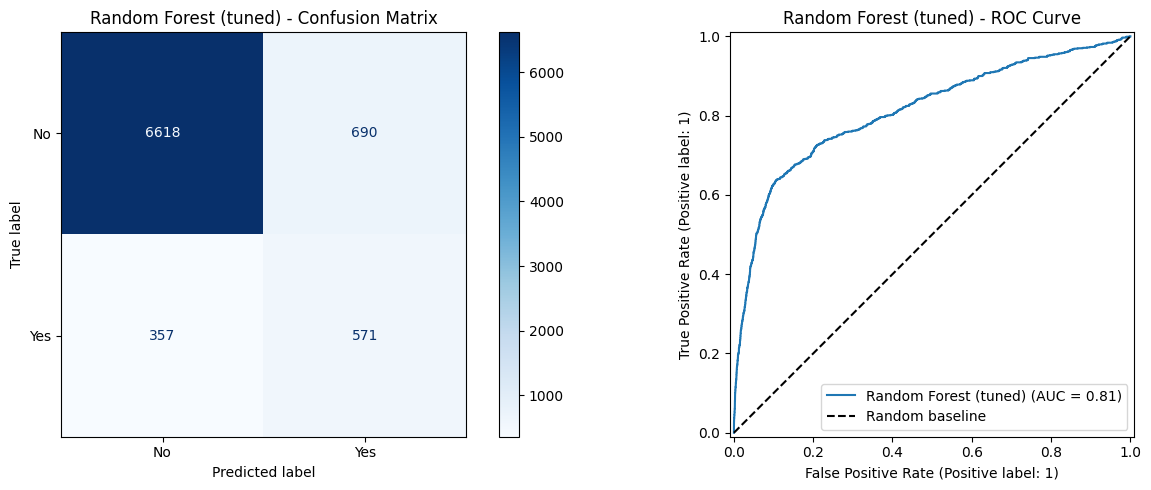

Đã lưu vào: results\EXP-16_RandomForest_tuned


In [32]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

def rf_metrics(y_true, y_pred, y_proba):
    """Tính 5 độ đo cho một phiên bản mô hình."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

def save_result(name, metrics, proba):
    """Lưu kết quả vào danh sách chung (thay dòng cũ nếu chạy lại)."""
    global all_results, all_probas
    if "all_results" not in globals():
        all_results = []
    if "all_probas" not in globals():
        all_probas = {}
    all_results[:] = [r for r in all_results if r["Model"] != name]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = proba

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

# Mô hình tốt nhất sau tinh chỉnh
model_rf_tuned = search_rf.best_estimator_
model_rf_tuned.set_params(n_jobs=-1)

y_pred_rf_tuned = model_rf_tuned.predict(X_test)
y_proba_rf_tuned = model_rf_tuned.predict_proba(X_test)[:, 1]

metrics_rf_tuned = rf_metrics(y_test, y_pred_rf_tuned, y_proba_rf_tuned)

print("===== RANDOM FOREST (TUNED) =====")
for k, v in metrics_rf_tuned.items():
    print(f"{k:<10}: {v:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test, y_pred_rf_tuned,
    target_names=["No", "Yes"], zero_division=0
))

# Confusion Matrix và ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf_tuned,
    display_labels=["No", "Yes"], cmap="Blues", ax=axes[0]
)
axes[0].set_title("Random Forest (tuned) - Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test, y_proba_rf_tuned, name="Random Forest (tuned)", ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("Random Forest (tuned) - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# Lưu kết quả vào danh sách chung
save_result("Random Forest (tuned)", metrics_rf_tuned, y_proba_rf_tuned)

save_experiment("EXP-16_RandomForest_tuned", model_rf_tuned, search_rf.best_params_, y_test, y_pred_rf_tuned, y_proba_rf_tuned)

##### 10.4.3. Nhận xét

**Nhận xét (điền sau khi chạy, bám sát số liệu thật):**

- Tham số tốt nhất: `max_depth` = ..., `min_samples_leaf` = ..., `max_features` = ..., `class_weight` = ...
- So với baseline (F1 ≈ 0,37, Recall ≈ 0,28, ROC-AUC ≈ 0,78): sau tinh chỉnh F1-score = ..., Recall = ..., ROC-AUC = ...
- Việc giới hạn độ sâu và tăng `min_samples_leaf` có/không giúp Random Forest cải thiện Recall? Giải thích: ...
- So sánh với SMOTE và chỉnh ngưỡng (mục 9.4): cách nào hiệu quả nhất? Có thể kết hợp tinh chỉnh với chỉnh ngưỡng ở nửa sau để tăng Recall hơn nữa.

### 11. So sánh trước và sau tinh chỉnh

_Nội dung sẽ được bổ sung._

### 12. Phân tích mô hình

#### 12.1. Độ quan trọng của đặc trưng (Feature Importance)

Xếp hạng các đặc trưng theo mức độ đóng góp vào dự đoán. Các cột phân loại đã được One-Hot nên xuất hiện dưới dạng `cat__tên-cột_giá-trị`. Decision Tree và Random Forest có sẵn `feature_importances_`; Logistic Regression (hệ số) và KNN (Permutation Importance) sẽ được bổ sung sau.

Top 10 đặc trưng quan trọng nhất của Decision Tree:
num__nr.employed         0.6288
num__cons.conf.idx       0.1278
num__cons.price.idx      0.0423
num__euribor3m           0.0422
num__pdays               0.0306
num__age                 0.0207
cat__month_oct           0.0195
num__campaign            0.0191
cat__poutcome_failure    0.0123
cat__default_unknown     0.0101
dtype: float64


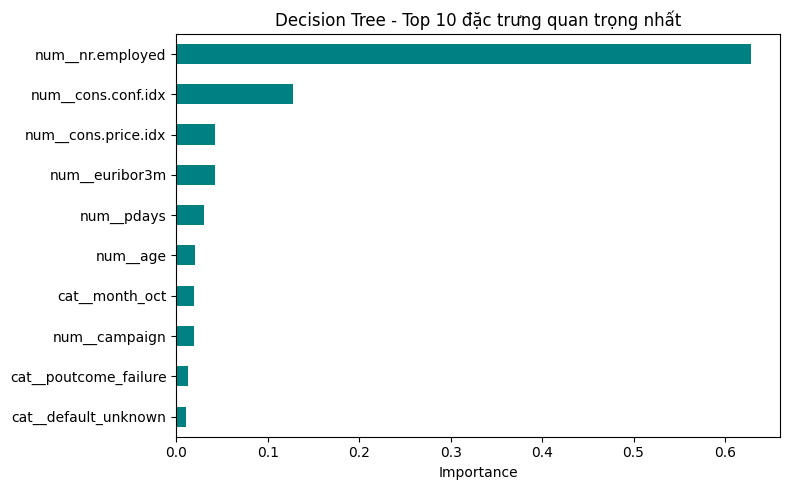

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Decision Tree
importance_dt = pd.Series(model_dt.feature_importances_, index=feature_names)
top10_dt = importance_dt.sort_values(ascending=False).head(10)

print("Top 10 đặc trưng quan trọng nhất của Decision Tree:")
print(top10_dt.round(4))

plt.figure(figsize=(8, 5))
top10_dt.sort_values().plot(kind="barh", color="teal")
plt.title("Decision Tree - Top 10 đặc trưng quan trọng nhất")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

Top 10 đặc trưng quan trọng nhất của Random Forest:
num__age               0.1347
num__euribor3m         0.1229
num__campaign          0.0753
num__nr.employed       0.0590
num__emp.var.rate      0.0427
num__cons.conf.idx     0.0311
num__cons.price.idx    0.0240
num__pdays             0.0218
cat__housing_no        0.0191
cat__housing_yes       0.0189
dtype: float64


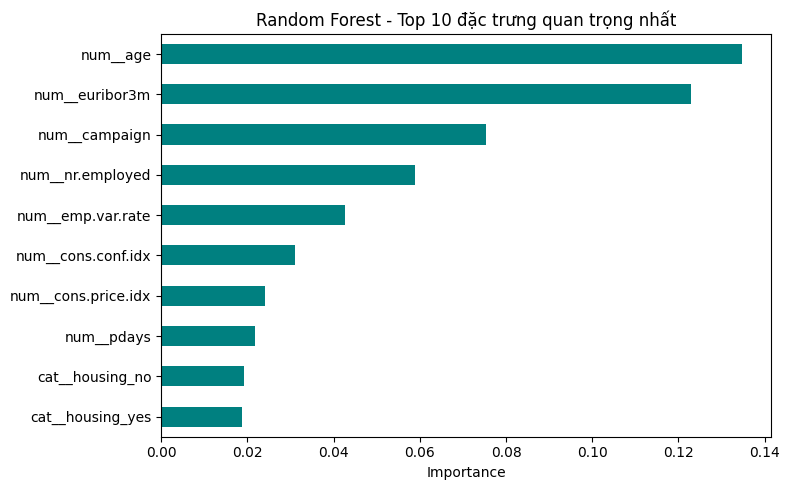

In [39]:
# Random Forest
importance_rf = pd.Series(model_rf.feature_importances_, index=feature_names)
top10_rf = importance_rf.sort_values(ascending=False).head(10)

print("Top 10 đặc trưng quan trọng nhất của Random Forest:")
print(top10_rf.round(4))

plt.figure(figsize=(8, 5))
top10_rf.sort_values().plot(kind="barh", color="teal")
plt.title("Random Forest - Top 10 đặc trưng quan trọng nhất")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Nhận xét (theo lần chạy với `random_state=42`, cập nhật lại nếu chạy ra số khác):**

- Decision Tree dựa chủ yếu vào `nr.employed` (≈ 0,63), tiếp theo là `cons.conf.idx` (≈ 0,13): quyết định của cây phụ thuộc rất nhiều vào các chỉ số kinh tế vĩ mô, và tập trung vào một biến duy nhất.
- Random Forest phân bố độ quan trọng đều hơn: `age` (≈ 0,13), `euribor3m` (≈ 0,12), `campaign` (≈ 0,08), `nr.employed` (≈ 0,06). Điều này phù hợp với việc Random Forest trung bình hóa nhiều cây dùng các đặc trưng khác nhau.
- Hai mô hình cùng nhấn mạnh nhóm chỉ số kinh tế (`euribor3m`, `nr.employed`, `emp.var.rate`) nên việc khách hàng đăng ký tiền gửi chịu ảnh hưởng đáng kể bởi bối cảnh lãi suất và kinh tế. Lưu ý độ quan trọng kiểu này có xu hướng thiên về các biến liên tục nhiều giá trị như `age`.

#### 12.2. Phân tích lỗi

_Nội dung sẽ được bổ sung._

### 13. Lưu mô hình

_Nội dung sẽ được bổ sung._

### 14. Kết luận, hạn chế, hướng phát triển

_Nội dung sẽ được bổ sung._